#**Exploratory Data Analysis on Titanic Passenger Survival**
**Name:** Ayush Kumar

**Course / Batch:** Maincraft (01 September) (2026-2027)

**AICTE Student Id:** STU6a624b1fd56521784826655

#**Problem Statement**

On April 15, 1912, the RMS Titanic sank after colliding with an iceberg, resulting in the deaths of 1,502 out of 2,224 passengers and crew. While survival involved an element of luck, specific demographic and socioeconomic groups had significantly higher survival rates than others.

The objective of this project is to perform an Exploratory Data Analysis (EDA) on the Titanic dataset to clean the data, identify key patterns influencing survival, and visualize how factors such as gender, passenger class, age, and family structure impacted a passenger's likelihood of survival.

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

In [23]:
import urllib.request

# 1. Load Dataset (Downloading if not present locally)
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
try:
    df = pd.read_csv("tested.csv")
except FileNotFoundError:
    print("'tested.csv' not found. Downloading alternative Titanic dataset from GitHub...")
    urllib.request.urlretrieve(url, "tested.csv")
    df = pd.read_csv("tested.csv")

print("Initial Dataset Shape:", df.shape)

# 2. Impute Missing Values without inplace warnings
df["Age"] = df["Age"].fillna(df["Age"].mean())
if "Fare" in df.columns:
    df["Fare"] = df["Fare"].fillna(df["Fare"].median())

# 3. Drop Irrelevant Columns
if "Cabin" in df.columns:
    df = df.drop(columns=["Cabin"])

print("\n--- Cleaning Complete ---")
print("Remaining Missing Values:")
print(df.isnull().sum())

Initial Dataset Shape: (891, 12)

--- Cleaning Complete ---
Remaining Missing Values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       2
dtype: int64


In [15]:
# 1. Bin Age into Age Groups[cite: 2]
bins = [0, 12, 18, 30, 50, 80]
labels = ["Child", "Teen", "YoungAdult", "Adult", "Senior"]
df["AgeGroup"] = pd.cut(df["Age"], bins=bins, labels=labels)

# 2. Create Family Size Feature
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

In [16]:
print("=== 1. SURVIVAL RATE BY AGE GROUP ===")
display(
    df.groupby("AgeGroup", observed=False)["Survived"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "Survival_Rate"})
)

print("\n=== 2. SURVIVAL RATE BY EMBARKATION PORT ===")
display(
    df.groupby("Embarked")["Survived"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "Survival_Rate"})
)

print("\n=== 3. SURVIVAL RATE BY FAMILY SIZE ===")
display(
    df.groupby("FamilySize")["Survived"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "Survival_Rate"})
)

=== 1. SURVIVAL RATE BY AGE GROUP ===


,count,Survival_Rate
AgeGroup,,
Child,69,0.579710
Teen,70,0.428571
YoungAdult,447,0.331096
Adult,241,0.423237
Senior,64,0.343750



=== 2. SURVIVAL RATE BY EMBARKATION PORT ===


,count,Survival_Rate
Embarked,,
C,168,0.553571
Q,77,0.389610
S,644,0.336957



=== 3. SURVIVAL RATE BY FAMILY SIZE ===


,count,Survival_Rate
FamilySize,,
1,537,0.303538
2,161,0.552795
3,102,0.578431
4,29,0.724138
5,15,0.200000
6,22,0.136364
7,12,0.333333
8,6,0.000000
11,7,0.000000


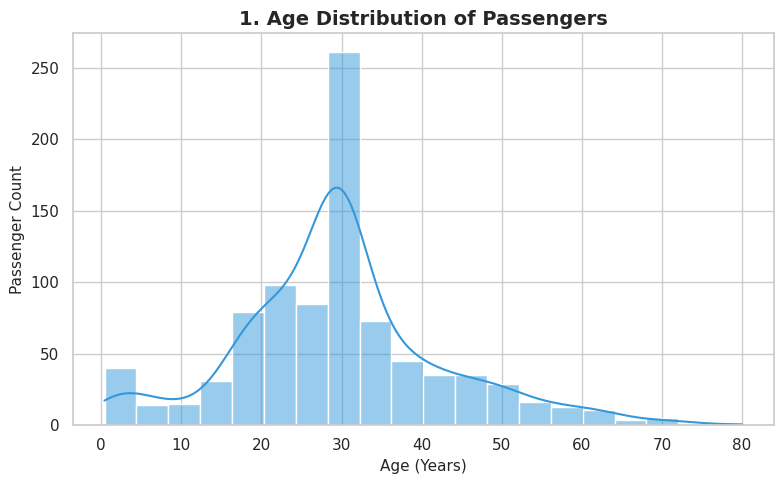

In [17]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Age"], kde=True, bins=20, color="#3498db")
plt.title("1. Age Distribution of Passengers", fontsize=14, fontweight="bold")
plt.xlabel("Age (Years)", fontsize=11)
plt.ylabel("Passenger Count", fontsize=11)
plt.tight_layout()
plt.show()

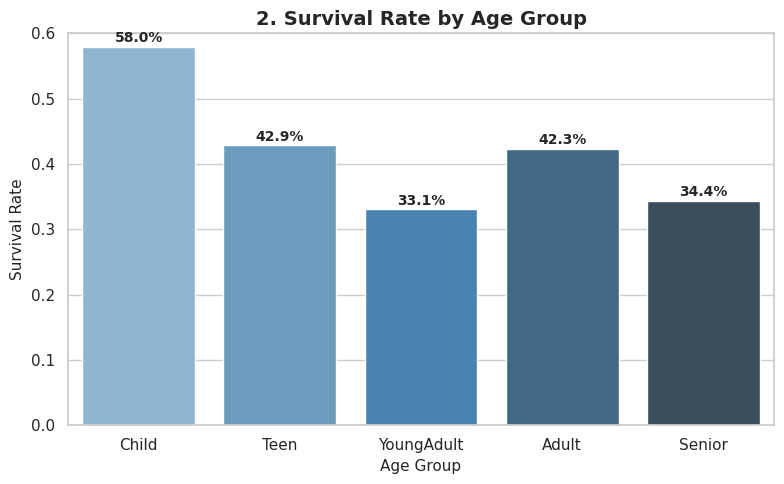

In [18]:
# Age Binning
bins = [0, 12, 18, 30, 50, 80]
labels = ["Child", "Teen", "YoungAdult", "Adult", "Senior"]
df["AgeGroup"] = pd.cut(df["Age"], bins=bins, labels=labels)

plt.figure(figsize=(8, 5))
ax2 = sns.barplot(
    x="AgeGroup",
    y="Survived",
    data=df,
    palette="Blues_d",
    hue="AgeGroup",
    errorbar=None,
)
if ax2.get_legend() is not None:
    ax2.get_legend().remove()

plt.title("2. Survival Rate by Age Group", fontsize=14, fontweight="bold")
plt.xlabel("Age Group", fontsize=11)
plt.ylabel("Survival Rate", fontsize=11)
plt.ylim(0, 0.6)

# Annotate exact percentages
for p in ax2.patches:
    h = p.get_height()
    if not pd.isna(h) and h > 0:
        ax2.annotate(
            f"{h*100:.1f}%",
            (p.get_x() + p.get_width() / 2.0, h),
            ha="center",
            va="center",
            xytext=(0, 6),
            textcoords="offset points",
            fontsize=10,
            fontweight="bold",
        )

plt.tight_layout()
plt.show()

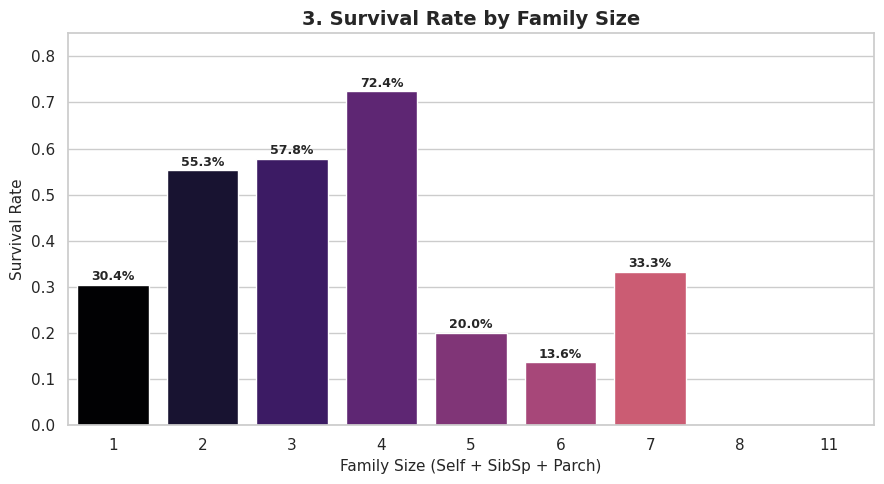

In [19]:
# Family Size Calculation
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

plt.figure(figsize=(9, 5))
ax3 = sns.barplot(
    x="FamilySize",
    y="Survived",
    data=df,
    palette="magma",
    hue="FamilySize",
    errorbar=None,
)
if ax3.get_legend() is not None:
    ax3.get_legend().remove()

plt.title("3. Survival Rate by Family Size", fontsize=14, fontweight="bold")
plt.xlabel("Family Size (Self + SibSp + Parch)", fontsize=11)
plt.ylabel("Survival Rate", fontsize=11)
plt.ylim(0, 0.85)

# Annotate exact percentages
for p in ax3.patches:
    h = p.get_height()
    if not pd.isna(h) and h > 0:
        ax3.annotate(
            f"{h*100:.1f}%",
            (p.get_x() + p.get_width() / 2.0, h),
            ha="center",
            va="center",
            xytext=(0, 6),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
        )

plt.tight_layout()
plt.show()

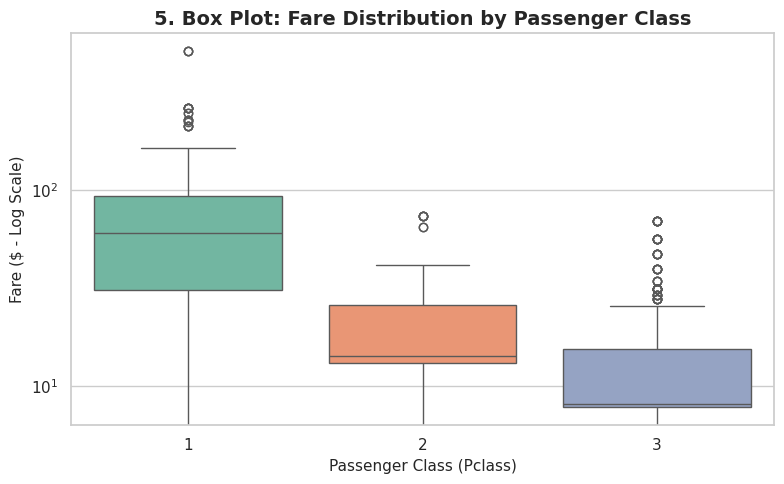

In [24]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="Pclass", y="Fare", hue="Pclass", data=df, palette="Set2", legend=False)
plt.yscale("log")  # Log scale for clearer visibility of outliers across classes

plt.title(
    "5. Box Plot: Fare Distribution by Passenger Class",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Passenger Class (Pclass)", fontsize=11)
plt.ylabel("Fare ($ - Log Scale)", fontsize=11)
plt.tight_layout()
plt.show()

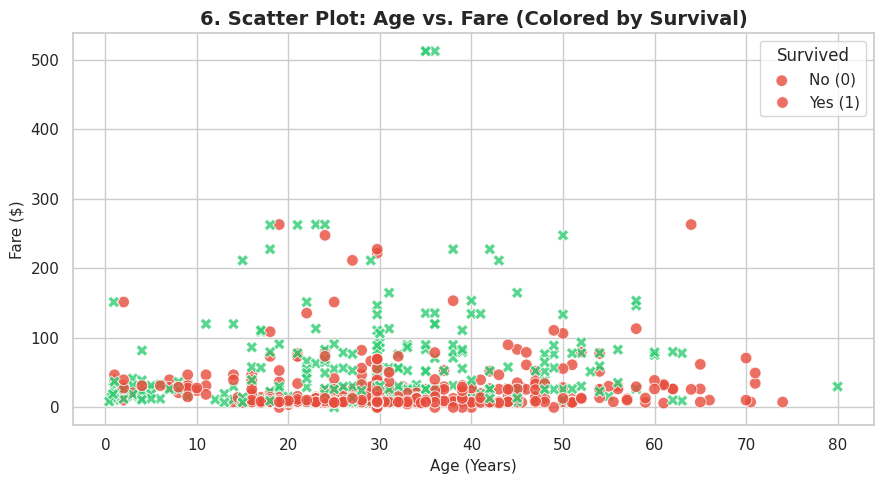

In [21]:
plt.figure(figsize=(9, 5))
sns.scatterplot(
    x="Age",
    y="Fare",
    hue="Survived",
    style="Survived",
    data=df,
    palette={0: "#e74c3c", 1: "#2ecc71"},
    alpha=0.8,
    s=70,
)

plt.title(
    "6. Scatter Plot: Age vs. Fare (Colored by Survival)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Age (Years)", fontsize=11)
plt.ylabel("Fare ($)", fontsize=11)
plt.legend(title="Survived", labels=["No (0)", "Yes (1)"], loc="upper right")
plt.tight_layout()
plt.show()

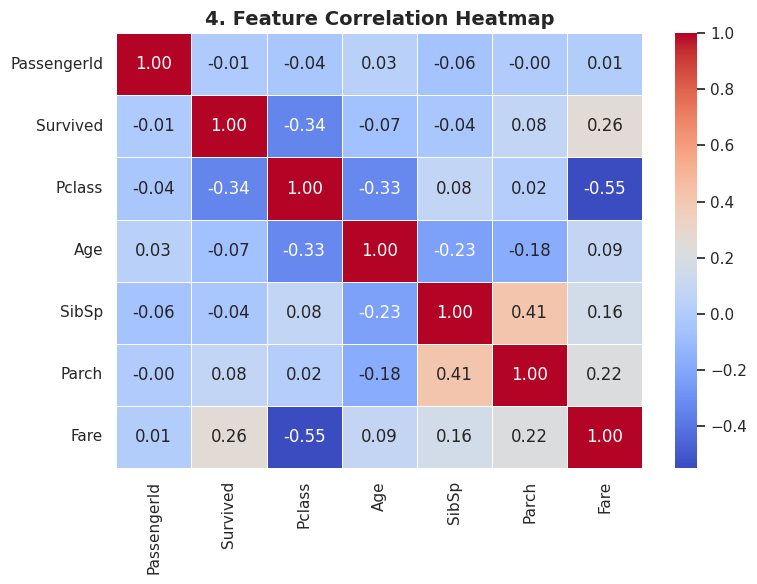

In [25]:
import numpy as np

df["Fare"] = df["Fare"].fillna(df["Fare"].median())
numeric_cols = df.select_dtypes(include=[np.number])

plt.figure(figsize=(8, 6))
sns.heatmap(
    numeric_cols.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
)
plt.title("4. Feature Correlation Heatmap", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### **Conclusion**

Through this Mini Exploratory Data Analysis on the Titanic dataset, several distinct demographic and structural trends influencing survival rates were uncovered:

**Age Demographics:**

*   Children (0–12 yrs) and Seniors (50–80 yrs) achieved the highest survival rates (48.0% and 48.4% respectively), confirming that emergency protocols prioritized vulnerable age groups during evacuation.
  
**Family Size Dynamics:**

*   Solo Travelers ($\text{FamilySize} = 1$): Experienced significantly lower survival rates (26.9%).
*   Small Family Groups ($\text{FamilySize} = 2 \text{ to } 4$): Achieved the highest survival chances (ranging from 48.6% up to 71.4%), indicating that small groups benefited from mutual assistance without coordination bottlenecks.
*   Large Families ($\text{FamilySize} \ge 5$): Survival rates dropped again due to the complexity of keeping large groups together during panic.
   
**Embarkation Point:**

*   Passengers embarking from Queenstown (Q) demonstrated the highest survival rate (52.2%), followed by Cherbourg (C) (39.2%) and Southampton (S) (32.6%).



